# 02 — Pré-processamento

Objetivo: transformar as gravações nas entradas dos modelos
(*tornar as entradas uniformes, normalizá-las e decidir entre sinal cru e features*).

Todo o código está em `src/features.py`, para a CNN e a RNN usarem **exatamente** o mesmo pré-processamento.
Este notebook justifica cada escolha e mostra o resultado.

| Passo | Decisão | Secção |
|---|---|---|
| Amplitude | média 0, desvio 1 **por gravação** | 1 |
| Duração uniforme | janelas de **5 s**, sem sobreposição; a última recua até ao fim do sinal (sem zeros) | 2 |
| Features | log-mel-espectrograma 64 × 313 (**CNN**) e sequência de 313 vetores MFCC de 13 (**RNN**) | 3 |
| Rótulo de cada janela | o do **paciente** (opção (a) do notebook 01) | 4 |
| Normalização das features | por banda mel / coeficiente MFCC, com médias e desvios **só do treino** | 5 |

In [1]:
import sys; sys.path.append("..")
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa.display

from src.data import load_recordings, load_split, load_audio, make_windows, SAMPLE_RATE
from src.metrics import CLASSES
from src.features import (normalize_audio, build_features, fit_standardizer, standardize,
                          WINDOW_S, N_FFT, HOP_LENGTH, N_MELS, FMAX, N_MFCC)

sns.set_theme(style="whitegrid")
COLORS = {"Present": "tab:red", "Unknown": "tab:orange", "Absent": "tab:blue"}
SUBSETS = ["train", "val", "test"]

recordings = load_recordings().merge(load_split(), on="patient_id")
print(f"{len(recordings)} gravações; janela {WINDOW_S} s; STFT n_fft={N_FFT}, hop={HOP_LENGTH}; {N_MELS} bandas mel até {FMAX} Hz; {N_MFCC} MFCC")

3163 gravações; janela 5.0 s; STFT n_fft=512, hop=64; 64 bandas mel até 1000 Hz; 13 MFCC


## 1. Normalização da amplitude

As gravações foram feitas com estetoscópios, pacientes e pressões diferentes, por isso o **volume** varia muito.
O modelo deve olhar para a **forma** do som, não para o volume. Duas opções:

- **dividir pelo pico** (máximo absoluto): sensível a um único estalo;
- **média 0 e desvio 1** (*z-score*): usa o sinal todo.

desvio-padrão por gravação: p1=0.014, mediana=0.038, p99=0.219 -> varia ~16x
gravações que tocam no máximo (|x| >= 0.999): 62.5%; nessas, mediana de 8 amostras saturadas


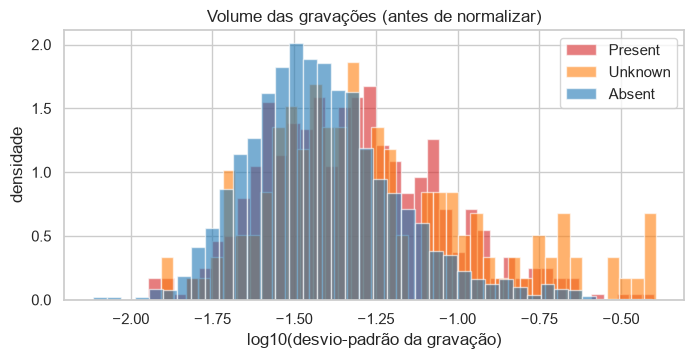

In [2]:
amp_rows = []
for rec in recordings.itertuples():
    x = load_audio(rec.wav)
    amp_rows.append({"std": x.std(), "peak": np.abs(x).max(), "n_saturated": int((np.abs(x) >= 0.999).sum())})
amp = pd.concat([recordings[["murmur"]], pd.DataFrame(amp_rows)], axis=1)

p1, p50, p99 = np.percentile(amp["std"], [1, 50, 99])
print(f"desvio-padrão por gravação: p1={p1:.3f}, mediana={p50:.3f}, p99={p99:.3f} -> varia ~{p99 / p1:.0f}x")
print(f"gravações que tocam no máximo (|x| >= 0.999): {(amp['n_saturated'] > 0).mean():.1%}; "
      f"nessas, mediana de {amp.loc[amp['n_saturated'] > 0, 'n_saturated'].median():.0f} amostras saturadas")

fig, ax = plt.subplots(figsize=(8, 3.5))
for c in CLASSES:
    ax.hist(np.log10(amp.loc[amp["murmur"] == c, "std"]), bins=40, alpha=0.6, density=True, label=c, color=COLORS[c])
ax.set_xlabel("log10(desvio-padrão da gravação)"); ax.set_ylabel("densidade"); ax.legend()
ax.set_title("Volume das gravações (antes de normalizar)")
plt.show()

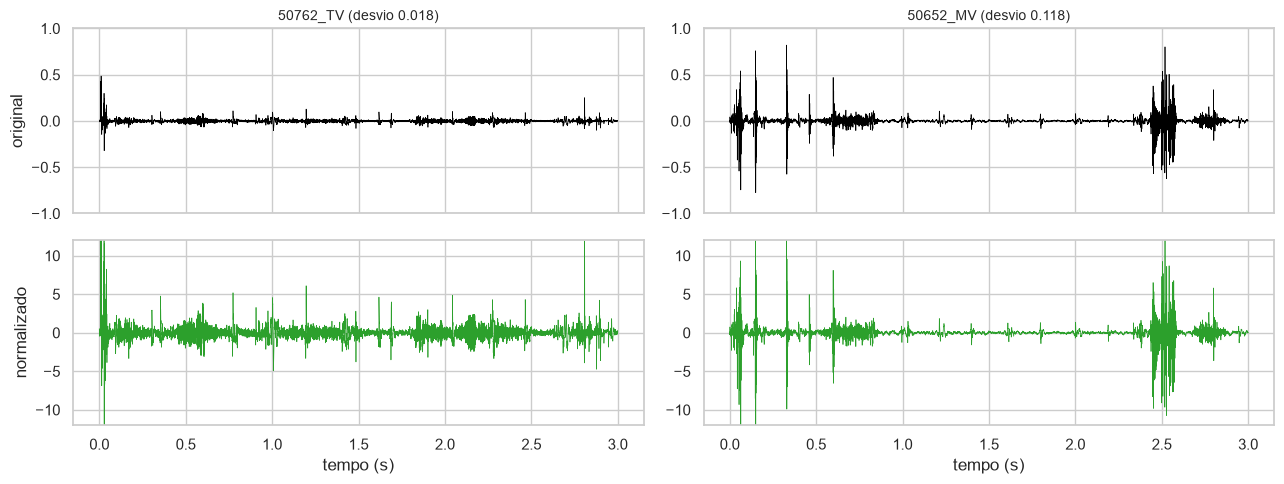

In [3]:
# Uma gravação baixa e uma alta (percentis 5 e 95 do desvio), antes e depois da normalização (primeiros 3 s).
quiet = amp["std"].sub(amp["std"].quantile(0.05)).abs().idxmin()
loud = amp["std"].sub(amp["std"].quantile(0.95)).abs().idxmin()
t = np.arange(3 * SAMPLE_RATE) / SAMPLE_RATE

fig, axes = plt.subplots(2, 2, figsize=(13, 5), sharex=True)
for col, idx in enumerate([quiet, loud]):
    x = load_audio(recordings.loc[idx, "wav"])[: 3 * SAMPLE_RATE]
    axes[0, col].plot(t, x, lw=0.5, color="black"); axes[0, col].set_ylim(-1, 1)
    axes[1, col].plot(t, normalize_audio(x), lw=0.5, color="tab:green"); axes[1, col].set_ylim(-12, 12)
    axes[0, col].set_title(f"{recordings.loc[idx, 'wav'].stem} (desvio {amp.loc[idx, 'std']:.3f})", fontsize=10)
axes[0, 0].set_ylabel("original"); axes[1, 0].set_ylabel("normalizado")
for ax in axes[1]: ax.set_xlabel("tempo (s)")
plt.tight_layout(); plt.show()

**Decisão: média 0 e desvio 1 por gravação** (`normalize_audio`).
- O volume varia ~16x entre gravações e depende de fatores que não controlamos (pressão do estetoscópio, aparelho,
  corpo do paciente). Queremos que o modelo aprenda a **forma** do som (onde está a energia no tempo e na frequência).
- **Atenção: o volume não é igual nas três classes.** O desvio mediano é 0.036 no *Absent*, 0.047 no *Present* e
  0.048 no *Unknown*, e o *Unknown* tem muito mais gravações muito altas (percentil 90: 0.185 contra 0.077 no *Absent*),
  provavelmente ruído ou fricção. Normalizar apaga esta pista, mas o ruído continua visível na forma do espectro.
  **Experiência possível:** dar ao modelo o volume original (ex.: `log10(desvio)`) como entrada extra e ver se a WA
  melhora, sobretudo no *Unknown*.
- A maioria das gravações tem **picos saturados** de poucas amostras (provavelmente batidas no estetoscópio).
  Dividir pelo pico faria a escala depender desses artefactos; o desvio-padrão quase não é afetado por eles.
- A normalização é feita **por gravação** (antes de cortar em janelas), por isso não usa informação de outros pacientes.

## 2. Janelas de duração fixa

As redes precisam de entradas do mesmo tamanho, mas as gravações duram entre 5.2 e 64.5 s. Cortamos cada gravação
em **janelas de 5 s** (`make_windows`):
- todas as gravações têm pelo menos 5 s, por isso nenhuma janela precisa de ser inventada;
- com a frequência cardíaca típica (~105 bpm, notebook 01), 5 s contêm ~9 batimentos: o padrão do sopro repete-se várias vezes;
- cada gravação dá várias janelas: mais exemplos de treino.

**A última janela.** Uma gravação de 21.5 s dá 4 janelas completas e sobra 1.5 s. Completar com zeros
(o comportamento original de `make_windows`) faria a última janela ter 70% de silêncio artificial. Com `pad_last=False`,
a última janela **recua** para terminar no fim do sinal: sobrepõe-se um pouco à anterior, mas só tem som real.

In [4]:
def window_counts(window_s, hop_s, pad_last):
    n, zeros = 0, 0
    for p in recordings["wav"]:
        x = load_audio(p)
        w = make_windows(x, window_s, hop_s, pad_last=pad_last)
        n += len(w); zeros += w.size - len(x) if pad_last else 0
    return n, zeros

rows = []
for label, (hop, pad) in {"sem sobreposição, zeros no fim": (None, True),
                          "sem sobreposição, última recuada (escolhida)": (None, False),
                          "50% sobreposição, última recuada": (WINDOW_S / 2, False)}.items():
    n, zeros = window_counts(WINDOW_S, hop, pad)
    rows.append({"opção": label, "janelas": n, "% de amostras que são zeros": round(100 * zeros / (n * WINDOW_S * SAMPLE_RATE), 1)})
display(pd.DataFrame(rows).set_index("opção"))

,janelas,% de amostras que são zeros
opção,,
"sem sobreposição, zeros no fim",16082,10.0
"sem sobreposição, última recuada (escolhida)",16082,0.0
"50% sobreposição, última recuada",27335,0.0


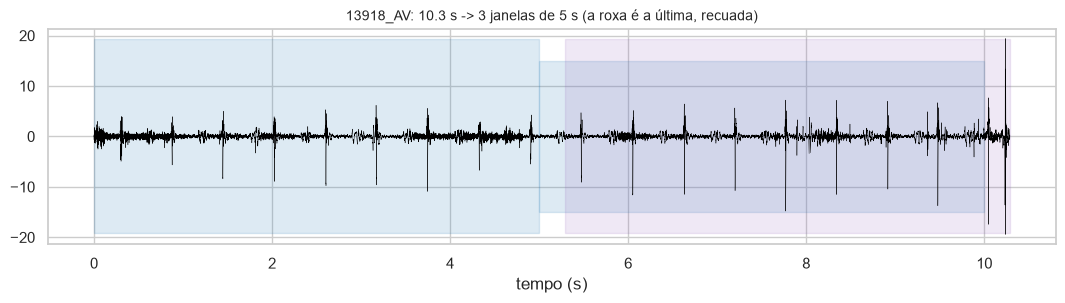

In [5]:
# Exemplo: onde caem as janelas numa gravação
rec = recordings.iloc[0]
x = normalize_audio(load_audio(rec["wav"]))
window = int(WINDOW_S * SAMPLE_RATE)
starts = list(range(0, len(x) - window + 1, window))   # a mesma lógica de make_windows(..., pad_last=False)
if starts[-1] + window < len(x):
    starts.append(len(x) - window)
starts = np.array(starts) / SAMPLE_RATE

fig, ax = plt.subplots(figsize=(13, 2.8))
ax.plot(np.arange(len(x)) / SAMPLE_RATE, x, lw=0.3, color="black")
for i, s in enumerate(starts):
    ax.axvspan(s, s + WINDOW_S, ymin=0.05 + 0.1 * (i % 2), ymax=0.95 - 0.1 * (i % 2), alpha=0.15,
               color="tab:purple" if i == len(starts) - 1 else "tab:blue")
ax.set_title(f"{rec['wav'].stem}: {len(x) / SAMPLE_RATE:.1f} s -> {len(starts)} janelas de {WINDOW_S:.0f} s (a roxa é a última, recuada)", fontsize=10)
ax.set_xlabel("tempo (s)")
plt.show()

**Decisão: janelas de 5 s, sem sobreposição, última recuada.** A sobreposição de 50% quase duplica o número de
janelas, mas as janelas novas são muito parecidas com as que já existem. Fica como **experiência** para o treino
(uma forma simples de *data augmentation*), comparando pela WA na validação.

## 3. Features: mel-espectrograma (CNN) e MFCC (RNN)

O significado dos parâmetros e das duas representações está explicado no fim da secção 6 do notebook 01.
Aqui calculamos as features de **todas** as janelas dos três conjuntos com `build_features`.

In [6]:
features = {}
for subset in SUBSETS:
    t0 = time.time()
    X_mel, meta = build_features(subset, "mel")
    X_mfcc, _ = build_features(subset, "mfcc")
    features[subset] = {"mel": X_mel, "mfcc": X_mfcc, "meta": meta}
    print(f"{subset:>5}: mel {X_mel.shape}, MFCC {X_mfcc.shape}, "
          f"{(X_mel.nbytes + X_mfcc.nbytes) / 1e6:.0f} MB, {time.time() - t0:.0f} s")

train: mel (11225, 64, 313), MFCC (11225, 313, 13), 1082 MB, 63 s


  val: mel (2431, 64, 313), MFCC (2431, 313, 13), 234 MB, 13 s


 test: mel (2426, 64, 313), MFCC (2426, 313, 13), 234 MB, 13 s


- **CNN:** cada janela é uma imagem de 64 bandas × 313 instantes (`X[:, None]` acrescenta o canal: `(n, 1, 64, 313)`).
- **RNN:** cada janela é uma sequência de 313 instantes, cada um com 13 MFCC: `(n, 313, 13)` (tempo primeiro,
  como o `batch_first=True` do PyTorch).
- Calcular tudo demora ~1–2 min, por isso **não guardamos as features em disco**: os notebooks dos modelos chamam
  `build_features` (assim ficam sempre sincronizados com `src/features.py`).
- `power_to_db` usa `top_db=None`: o valor por omissão (`top_db=80`) corta relativamente ao máximo do **lote** inteiro,
  o que faria a feature de uma janela depender das outras janelas calculadas ao mesmo tempo.

## 4. Rótulo de cada janela

Cada janela herda o rótulo do **paciente** (opção (a) do notebook 01). A tabela `meta` guarda também o paciente,
o local, a gravação e `murmur_audible`, para:
- juntar as previsões das janelas → gravação → paciente (o guião exige **uma previsão por paciente**);
- testar mais tarde as opções (b) e (c) sem refazer as features.

In [7]:
counts = pd.DataFrame({s: features[s]["meta"]["murmur"].value_counts() for s in SUBSETS}).T[CLASSES]
counts["total"] = counts.sum(axis=1)
counts["janelas por paciente"] = [round(len(features[s]["meta"]) / features[s]["meta"]["patient_id"].nunique(), 1) for s in SUBSETS]
print("Janelas por classe e conjunto:"); display(counts)

m = features["train"]["meta"]
present = m[m["murmur"] == "Present"]
print(f"treino: {len(present)} janelas Present, das quais {(~present['murmur_audible']).sum()} "
      f"({(~present['murmur_audible']).mean():.0%}) vêm de locais sem sopro audível")
print("\nproporção de classes nas janelas do treino (%):", (100 * m["murmur"].value_counts(normalize=True)).round(1).reindex(CLASSES).to_dict())

Janelas por classe e conjunto:


murmur,Present,Unknown,Absent,total,janelas por paciente
train,2148,539,8538,11225,17.1
val,455,122,1854,2431,17.1
test,459,117,1850,2426,17.1


treino: 2148 janelas Present, das quais 351 (16%) vêm de locais sem sopro audível

proporção de classes nas janelas do treino (%): {'Present': 19.1, 'Unknown': 4.8, 'Absent': 76.1}


## 5. Normalização das features

As features têm escalas muito diferentes de banda para banda e de coeficiente para coeficiente (ex.: o MFCC 0 tem
valores na casa das centenas, os últimos perto de 0). Sem normalizar, as maiores dominam o treino.
Normalizamos cada **banda mel** e cada **coeficiente MFCC** para média 0 e desvio 1.

**As médias e desvios são calculados só no treino** e aplicados igual à validação e ao teste. Calculá-los com
validação ou teste seria usar informação desses conjuntos para preparar o modelo (o guião proíbe usar o teste para
qualquer decisão).

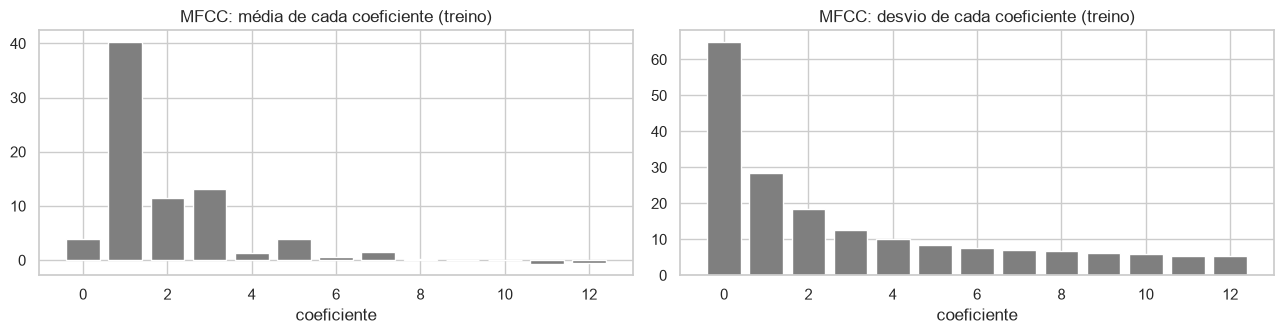

Depois de normalizar (treino ~0/1 por construção; validação e teste ficam perto, mas não exatamente):


média  desvio
train mel  -0.000   1.000
      mfcc  0.000   1.000
val   mel   0.040   1.002
      mfcc  0.002   1.005
test  mel   0.013   1.001
      mfcc -0.006   1.007

In [8]:
stats = {kind: fit_standardizer(features["train"][kind], kind) for kind in ["mel", "mfcc"]}

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].bar(range(N_MFCC), stats["mfcc"][0].ravel(), color="tab:gray")
axes[0].set_title("MFCC: média de cada coeficiente (treino)"); axes[0].set_xlabel("coeficiente")
axes[1].bar(range(N_MFCC), stats["mfcc"][1].ravel(), color="tab:gray")
axes[1].set_title("MFCC: desvio de cada coeficiente (treino)"); axes[1].set_xlabel("coeficiente")
plt.tight_layout(); plt.show()

for s in SUBSETS:
    for kind in ["mel", "mfcc"]:
        features[s][kind] = standardize(features[s][kind], stats[kind])

summary = {(s, kind): {"média": features[s][kind].mean(), "desvio": features[s][kind].std()}
           for s in SUBSETS for kind in ["mel", "mfcc"]}
print("Depois de normalizar (treino ~0/1 por construção; validação e teste ficam perto, mas não exatamente):")
display(pd.DataFrame(summary).T.round(3))

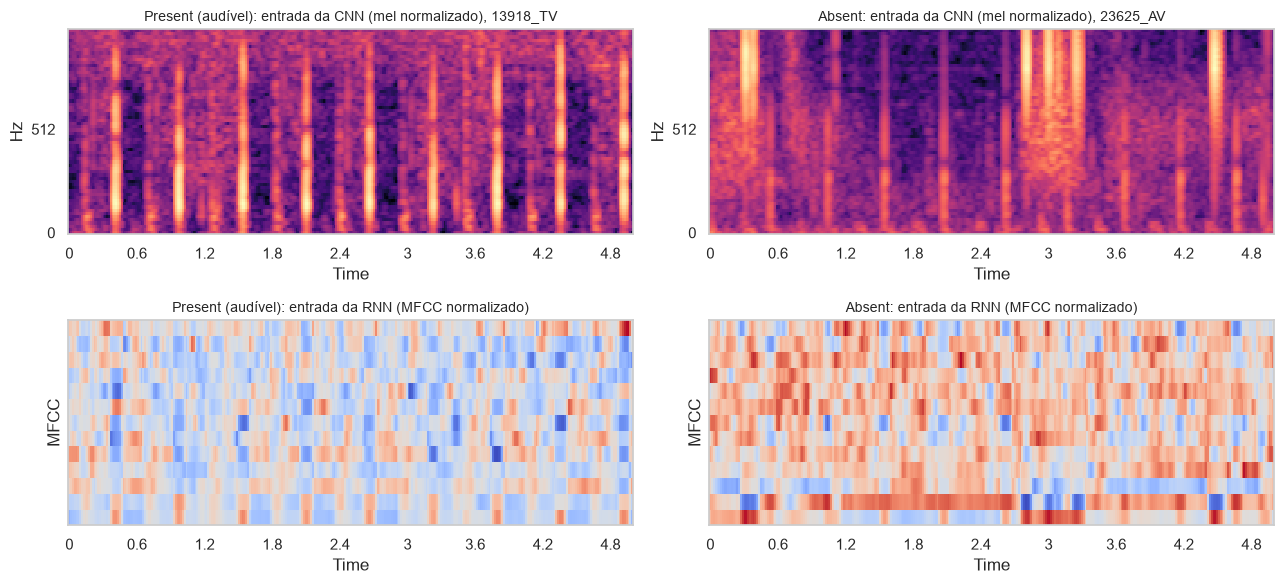

In [9]:
# Entradas finais (já normalizadas) de uma janela Present com sopro audível e de uma Absent
meta = features["train"]["meta"]
examples = {"Present (audível)": meta.index[meta["murmur_audible"]][0], "Absent": meta.index[meta["murmur"] == "Absent"][0]}

fig, axes = plt.subplots(2, 2, figsize=(13, 6))
for col, (name, i) in enumerate(examples.items()):
    librosa.display.specshow(features["train"]["mel"][i], sr=SAMPLE_RATE, hop_length=HOP_LENGTH, x_axis="time",
                             y_axis="mel", fmax=FMAX, ax=axes[0, col], cmap="magma")
    axes[0, col].set_title(f"{name}: entrada da CNN (mel normalizado), {meta.loc[i, 'recording']}", fontsize=10)
    librosa.display.specshow(features["train"]["mfcc"][i].T, sr=SAMPLE_RATE, hop_length=HOP_LENGTH, x_axis="time",
                             ax=axes[1, col], cmap="coolwarm")
    axes[1, col].set_ylabel("MFCC"); axes[1, col].set_title(f"{name}: entrada da RNN (MFCC normalizado)", fontsize=10)
plt.tight_layout(); plt.show()

## 6. Resumo e próximos passos

**Entradas prontas para os modelos** (já normalizadas):

| Conjunto | Pacientes | Gravações | Janelas | CNN `(n, 1, 64, 313)` | RNN `(n, 313, 13)` |
|---|---|---|---|---|---|
| treino | 658 | 2210 | 11 225 | mel-espectrograma | MFCC |
| validação | 142 | 474 | 2 431 | mel-espectrograma | MFCC |
| teste | 142 | 479 | 2 426 | mel-espectrograma | MFCC |

Em média ~17 janelas por paciente. Calcular tudo demora ~1.5 min; os notebooks dos modelos usam `build_features`.

**O que aprendemos aqui**
- **As proporções das classes mudam ao passar para janelas.** Nos pacientes são 19% / 7% / 74%; nas janelas do treino
  são 19% / **4.8%** / 76%. Os pacientes *Unknown* têm menos gravações (2.3 por paciente, contra 3.4 nas outras classes),
  por isso o *Unknown* fica ainda mais raro. Os pesos de classe na loss devem ser calculados sobre as **janelas** do treino.
- 351 das 2148 janelas *Present* do treino (16%) vêm de locais sem sopro audível (opção (a) dos rótulos; ver notebook 01).
- As médias e desvios do treino servem bem para a validação e o teste (ficam perto de 0 e 1), por isso a normalização
  não depende do conjunto.

**Próximos passos (notebooks dos modelos)**
1. **Pesos de classe** na loss, calculados nas janelas do treino.
2. **Uma previsão por paciente:** média das probabilidades das janelas → previsão por gravação → paciente *Present* se
   alguma gravação for *Present* (regra a afinar na validação, ex.: o que fazer com *Unknown*).
3. **Experiências** (escolher pela WA na validação): sobreposição de 50% no treino (27 335 janelas), `fmax=2000`,
   `n_fft` 256/1024, deltas do MFCC, opções (b)/(c) dos rótulos, volume original como entrada extra.